<a href="https://colab.research.google.com/github/HuriyaAhmerr/AIP/blob/main/AIP_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Universal Plus – E-Mail Marketing Targeting
**IB9BW0 Analytics in Practice**

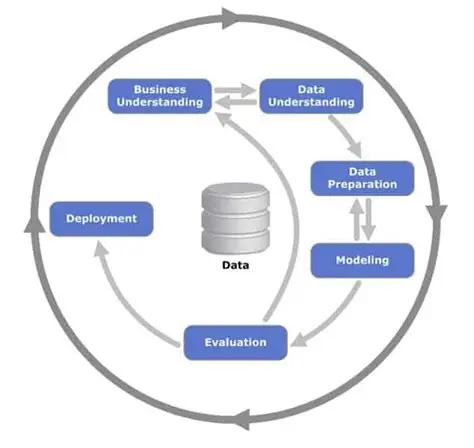





## 1. Business Understanding

**Business figures from the board:**
- Cost per e-mail: £3.50
- Value of a visit: £93 average spend × 30% margin ≈ £28


**Business problem:**

Today, decisions about who receives a campaign e-mail are mostly made by rules of thumb or at random. Targeting uninterested customers costs money, and several past campaigns were not successful.

The company wants a system that predicts whether each customer will visit the shop after a campaign.

-------------------------------------------------

**Analytics problem:**

for each customer, predict whether they will visit the shop in the two weeks after the campaign (`visit` = 1 or 0), using only information available *before* the campaign plus the e-mail they receive.

As the answer is a category, this is a *classification* problem. So estimate each customer's chance of visiting under each choice (Men's e-mail, Women's e-mail, no e-mail), then convert these into expected profit (chance of visit × £28 − £3.50 per e-mail), and finally recommend the most profitable choice.




## 2. Data Understanding


### The Datasets
| File | Rows | Columns | Contains `visit`? |
|---|---|---|---|
| `campaign_data.csv` | 52,000 | 21 | Yes |
| `next_campaign.csv` | 12,000 | 20 | No |

**campaign_data.csv** – contains the 52,000 customers who took part in the test campaign. For each
customer it records 21 attributes, including the e-mail they received and whether they visited the shop.  

**next_campaign.csv** – contains 12,000 further customers from the same campaign. It holds the same
information as the first file, except that it does not say whether these customers visited the shop. Universal
Plus has shared this file to see how your system would be used in its next campaign


In [29]:
print(open("readme.txt").read())   # delete this at the end

1. Title: E-Mail Marketing

Universal Plus randomly sent an e-mail marketing campaign to some of its customers.
Some customers received a campaign on women's products, some received a campaign on men's products,
and some did not receive an e-mail campaign at all.
The company collected data for all of these customers (including the ones who did not receive the campaign)
during the two weeks following the e-mail campaign.

2. Files and number of instances

   campaign_data.csv            52,000 customers, all 21 attributes listed below.
   next_campaign.csv		12,000 further customers from the same campaign. All attributes 				are provided except `visit`, which has been withheld. Universal 				Plus has shared this file to see how your system would be used 					in its next campaign.

3. Number of attributes: 21

4. Attribute information:

  1) Customer_ID: Customer identification number
  2) recency: Months since last purchase before the marketing campaign
  3) purchase_segment: Categorisat

-----
### 2.1 Load the data and take a first look

In [30]:
# Import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_selection import mutual_info_classif
from sklearn.tree import DecisionTreeClassifier, plot_tree


In [31]:
# Load the files.
df = pd.read_csv("campaign_data.csv")
nxt = pd.read_csv("next_campaign.csv")

# How many rows and columns?
print(df.shape)
print(nxt.shape)

(52000, 21)
(12000, 20)


In [32]:
# The first five rows
df.head()

,Customer_ID,recency,purchase_segment,purchase,mens,womens,zip_area,new_customer,channel,email_segment,...,dependent,account,employed,phone,delivery,marriage,payment_card,satisfaction_score,spend,visit
0,30000001,12.0,1) 0 - 100,81.61,1,0,Urban,0,Phone,No E-Mail,...,1,1,1,1,1,0,1,NaN,0.0,0
1,30000004,NaN,3) 200 - 350,258.74,1,0,Urban,0,Multichannel,Mens E-Mail,...,1,1,1,1,3,0,1,8.0,0.0,0
2,30000005,6.0,3) 200 - 350,239.96,1,0,Suburban,0,Phone,No E-Mail,...,0,1,1,1,1,1,1,NaN,0.0,0
3,30000006,7.0,3) 200 - 350,268.18,1,1,Rural,1,Web,Womens E-Mail,...,1,1,1,1,3,2,0,5.0,0.0,0
4,30000007,1.0,3) 200 - 350,311.52,0,1,Suburban,0,Web,No E-Mail,...,0,1,1,1,3,1,1,8.0,0.0,0


In [33]:
# The structure: column names, data types and the number of non-missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52000 entries, 0 to 51999
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer_ID         52000 non-null  int64  
 1   recency             48238 non-null  float64
 2   purchase_segment    51977 non-null  object 
 3   purchase            52000 non-null  float64
 4   mens                52000 non-null  int64  
 5   womens              52000 non-null  int64  
 6   zip_area            51221 non-null  object 
 7   new_customer        52000 non-null  int64  
 8   channel             51241 non-null  object 
 9   email_segment       52000 non-null  object 
 10  age                 49987 non-null  float64
 11  dependent           52000 non-null  int64  
 12  account             52000 non-null  int64  
 13  employed            52000 non-null  int64  
 14  phone               52000 non-null  int64  
 15  delivery            52000 non-null  int64  
 16  marr

In [34]:
# Summary statistics of the numerical columns: check min and max for odd values
df.describe().round(2)

,Customer_ID,recency,purchase,mens,womens,new_customer,age,dependent,account,employed,phone,delivery,marriage,payment_card,satisfaction_score,spend,visit
count,52000.00,48238.00,52000.00,52000.00,52000.00,52000.0,49987.00,52000.00,52000.0,52000.00,52000.00,52000.00,52000.00,52000.00,20918.00,51965.00,52000.00
mean,30032019.63,6.04,241.62,0.55,0.55,0.5,35.37,0.38,1.0,1.00,0.94,1.71,1.04,0.74,7.00,15.26,0.16
std,18483.14,3.45,256.75,0.50,0.50,0.5,8.94,0.49,0.0,0.04,0.23,0.93,0.87,0.44,1.45,42.98,0.37
min,30000001.00,1.00,25.00,0.00,0.00,0.0,19.00,0.00,1.0,0.00,0.00,1.00,0.00,0.00,2.00,0.00,0.00
25%,30015996.75,3.00,64.19,0.00,0.00,0.0,28.00,0.00,1.0,1.00,1.00,1.00,0.00,0.00,6.00,0.00,0.00
50%,30032015.50,6.00,156.82,1.00,1.00,1.0,34.00,0.00,1.0,1.00,1.00,1.00,1.00,1.00,7.00,0.00,0.00
75%,30048071.25,9.00,324.84,1.00,1.00,1.0,41.00,1.00,1.0,1.00,1.00,3.00,2.00,1.00,8.00,0.00,0.00
max,30064000.00,12.00,3387.49,1.00,1.00,1.0,62.00,1.00,1.0,1.00,1.00,3.00,2.00,1.00,10.00,499.00,1.00


**Findings from `describe()`**
- **`purchase`** ranges from £25 to £3,387, with a mean of £242 but a median of only £157. The data is **right-skewed**: most customers spend little, and a few spend a lot. The high values are plausible (big spenders), so we keep them.
- **`recency`** (1–12 months), **`age`** (19–62) and **`satisfaction_score`** (2–10) all lie within plausible ranges. No obvious errors.
- **`account`** has a standard deviation of 0: every customer has the value 1, so it carries no information.
- **`employed`** has a mean of 0.998: almost every customer is employed, so it is nearly constant.
- **`spend`**: the median is 0, so most customers spent nothing after the campaign. It is also an after-campaign value (leakage).
- **`delivery`** and **`marriage`** show a mean and a standard deviation, but these are meaningless because the numbers are category codes (e.g. delivery: 1 = home, 2 = work, 3 = multiple)., not quantities. They need to be treated as categories.
- **`Customer_ID`**'s statistics are meaningless too: it is an identifier.


-----
## 2.2 Investigating what does "missing" mean here?


In [35]:
# Count every value in the text columns, including missing values
for column in ["zip_area", "channel", "purchase_segment"]:
    print(df[column].value_counts(dropna=False), "\n")

zip_area
Suburban    23055
Urban       20476
Rural        7690
NaN           779
Name: count, dtype: int64 

channel
Web             22516
Phone           22493
Multichannel     6232
NaN               759
Name: count, dtype: int64 

purchase_segment
1) 0 - 100        18776
2) 100 - 200      11576
3) 200 - 350       9878
4) 350 - 500       5137
5) 500 - 750       4041
6) 750 - 1,000     1508
7) 1,000 +         1061
NaN                  23
Name: count, dtype: int64 



In [36]:
# Look at the file as plain text: no guessing what is missing
# keep_default_na=False: turn nothing into NaN
raw = pd.read_csv("campaign_data.csv", keep_default_na=False)

# How many blank cells in each column that has missing values?
for column in ["recency", "age", "satisfaction_score", "zip_area", "channel", "purchase_segment"]:
    print(column, ":", (raw[column] == "").sum(), "blank cells")

recency : 3762 blank cells
age : 2013 blank cells
satisfaction_score : 31082 blank cells
zip_area : 779 blank cells
channel : 759 blank cells
purchase_segment : 23 blank cells


**Findings**

The number of blank cells in the raw file matches the number of missing values pandas found (e.g. 779 for `zip_area`). All missing values are **blank cells**: nothing was recorded.


-----
## 2.3 The target and the effect of the e-mails


In [37]:
# How rare are visits?
print(df["visit"].value_counts())
print(df["visit"].value_counts(normalize=True).round(3))

visit
0    43476
1     8524
Name: count, dtype: int64
visit
0    0.836
1    0.164
Name: proportion, dtype: float64


In [38]:
# Business figures from the brief
EMAIL_COST = 3.50            # £ per e-mail
VISIT_VALUE = 0.30 * 93      # £ profit per visit ≈ £27.90


# Visit rate in each e-mail group
visit_rates = df.groupby("email_segment")["visit"].mean()
print(visit_rates.round(3), "\n")

# Lift = increase in visit rate compared with no e-mail
for email in ["Mens E-Mail", "Womens E-Mail"]:
    increase_of = visit_rates[email] - visit_rates["No E-Mail"]
    print(f"{email}:   increase_of = {  increase_of:.1%} compared with no e-mail")


email_segment
Mens E-Mail      0.221
No E-Mail        0.072
Womens E-Mail    0.198
Name: visit, dtype: float64 

Mens E-Mail:   increase_of = 14.9% compared with no e-mail
Womens E-Mail:   increase_of = 12.6% compared with no e-mail





  **Findings**
- **Target:** only 16.4% of customers visited the shop (8,524 of 52,000).

 The data is **imbalanced**: a model could reach 83.6% accuracy by always predicting "no visit", so accuracy alone is not a useful measure. We need measures that focus on the visitors.

- **E-mail effect:** both e-mails increase visits compared with no e-mail (7.2%):
  - Men's e-mail: 22.1%, an increase of 14.9 percentage points
  - Women's e-mail: 19.8%, an increase of 12.6 percentage points


# 3. Data Preparation

**Cleaning plan**

| Step | Action | Justification |
|---|---|---|
| 3.1 | Drop `Customer_ID`, `account`, `employed`, `spend` | ID is not a quantity; `account` always 1; `employed` 99.8% the same; `spend` is recorded after the campaign (leakage) |
| 3.2 | Check category labels | Inconsistent labels create false categories |
| 3.3 | Keep high `purchase` values | Max £3,387 is plausible; removing it would lose real big spenders |
| 3.4 | Fill missing numbers with the median and add a 0/1 "was missing" column. Fill missing categories with "Missing". Rebuild `purchase_segment` from `purchase`. | Deleting rows would lose too many customers (60% have no `satisfaction_score`). The median isn't pulled by extreme values. The 0/1 column remembers which values were missing. |
| 3.5 | `delivery`, `marriage` and text columns → categories | They are codes, not quantities |


*Medians are calculated on the training set only, to avoid leakage.*

-----
## 3.1 Remove columns: `Customer_ID`, `account`, `employed`, `spend`

`Customer_ID` is an identifier, `account` and `employed` (almost) never change, and `spend` is only known after the campaign.

In [39]:
# Check the columns with (almost) one value
for column in ["account", "employed"]:
    print(df[column].value_counts(), "\n")

account
1    52000
Name: count, dtype: int64 

employed
1    51914
0       86
Name: count, dtype: int64 



In [40]:
# Leakage check: did every customer who spent money also visit?
print(df.loc[df["spend"] > 0, "visit"].value_counts())

visit
1    8449
Name: count, dtype: int64


**Findings:**

`account` is 1 for all 52,000 customers, and `employed` is 1 for all but 86 (0.2%).

**Justification:** a column that (almost) never changes cannot help a model tell customers apart, so we remove both.


Additionally, all 8,449 customers who spent money also visited the shop.

**Justification:** `spend` is only known after the campaign and gives away the answer (data leakage), so we remove it.

In [41]:
# Remove the ID, (almost) constant and leaking columns
df = df.drop(columns=["Customer_ID", "account", "employed", "spend"])
df.head()

,recency,purchase_segment,purchase,mens,womens,zip_area,new_customer,channel,email_segment,age,dependent,phone,delivery,marriage,payment_card,satisfaction_score,visit
0,12.0,1) 0 - 100,81.61,1,0,Urban,0,Phone,No E-Mail,42.0,1,1,1,0,1,NaN,0
1,NaN,3) 200 - 350,258.74,1,0,Urban,0,Multichannel,Mens E-Mail,38.0,1,1,3,0,1,8.0,0
2,6.0,3) 200 - 350,239.96,1,0,Suburban,0,Phone,No E-Mail,26.0,0,1,1,1,1,NaN,0
3,7.0,3) 200 - 350,268.18,1,1,Rural,1,Web,Womens E-Mail,30.0,1,1,3,2,0,5.0,0
4,1.0,3) 200 - 350,311.52,0,1,Suburban,0,Web,No E-Mail,45.0,0,1,3,1,1,8.0,0


-----
## 3.2 Category labels

Labels written differently would be treated as different groups, so we check every text column.

In [42]:
# Check the labels of every text column
for column in ["purchase_segment", "zip_area", "channel", "email_segment"]:
    print(df[column].value_counts(), "\n")

purchase_segment
1) 0 - 100        18776
2) 100 - 200      11576
3) 200 - 350       9878
4) 350 - 500       5137
5) 500 - 750       4041
6) 750 - 1,000     1508
7) 1,000 +         1061
Name: count, dtype: int64 

zip_area
Suburban    23055
Urban       20476
Rural        7690
Name: count, dtype: int64 

channel
Web             22516
Phone           22493
Multichannel     6232
Name: count, dtype: int64 

email_segment
No E-Mail        17334
Mens E-Mail      17334
Womens E-Mail    17332
Name: count, dtype: int64 



**Findings:** every text column has consistent labels (no variations such as "urban" vs "Urban"). The three e-mail groups are almost equal in size (17,334 / 17,334 / 17,332), as expected from random assignment.

**Justification:** no label fixes are needed, so the columns are kept as they are.

-----
## 3.3 Implausible values

`describe()` in 2.1 showed plausible ranges for all numbers except possibly `purchase` (max £3,387). We look at the highest values.

In [43]:
# Sort by purchase to see the highest values
df.sort_values("purchase", ascending=False).head()

,recency,purchase_segment,purchase,mens,womens,zip_area,new_customer,channel,email_segment,age,dependent,phone,delivery,marriage,payment_card,satisfaction_score,visit
47574,1.0,"7) 1,000 +",3387.49,1,1,Urban,1,NaN,No E-Mail,41.0,0,1,3,0,1,9.0,0
41081,1.0,"7) 1,000 +",3290.76,1,1,NaN,1,Multichannel,No E-Mail,23.0,0,1,2,2,0,9.0,1
3887,7.0,"7) 1,000 +",3055.10,0,1,Suburban,1,Web,Mens E-Mail,29.0,0,1,1,2,1,NaN,0
40755,1.0,"7) 1,000 +",2884.70,0,1,Urban,1,Web,Womens E-Mail,30.0,0,1,2,1,1,6.0,1
24029,NaN,"7) 1,000 +",2856.69,1,1,Urban,1,Phone,No E-Mail,NaN,1,1,2,0,1,9.0,1


**Findings:** the highest purchases (£2,857–£3,387) decrease gradually with no extreme jump, and all match their `purchase_segment`.

**Justification:** these look like genuine big spenders, not errors, so we keep them. Removing them would lose valuable customers.

-----
## 3.4 Missing values

We fill missing values instead of deleting rows: `satisfaction_score` alone is missing for 60% of customers (2.2), so deleting rows would lose most of the data.

**Missing flags:** before filling, we add a column that is **1** where the value was missing and **0** where it was observed. After filling, the gaps are no longer visible, so the flag keeps that information for the model.

In [44]:
# Add missing flags BEFORE filling (1 = was missing, 0 = observed)
for column in ["recency", "age", "satisfaction_score"]:
    df[column + "_missing"] = df[column].isnull().astype(int)

# Do customers with a missing value visit more or less often?
for column in ["recency", "age", "satisfaction_score"]:
    print(column, df.groupby(column + "_missing")["visit"].mean().round(3).to_dict())

recency {0: 0.153, 1: 0.306}
age {0: 0.157, 1: 0.33}
satisfaction_score {0: 0.204, 1: 0.137}


**Findings:** missing values are linked to visiting:
- `recency` missing: 30.6% visit vs 15.3% when observed (twice as often)
- `age` missing: 33.0% vs 15.7% (twice as often)
- `satisfaction_score` missing: 13.7% vs 20.4% (less often)

**Justification:** the fact that a value is missing carries information, so we keep it as a 0/1 flag. The gaps themselves are filled with the median **after** the train/test split (training-set medians only, to avoid leakage).

### Categories with missing values

`zip_area` (779) and `channel` (759) have a few missing values. so we will fill them with an explicit **"Missing"** category, so the model can learn whether these customers behave differently.

In [45]:
# Fill missing categories with "Missing"
for column in ["zip_area", "channel"]:
    df[column] = df[column].fillna("Missing")

# Do these customers visit more or less often?
for column in ["zip_area", "channel"]:
    print(df.groupby(column)["visit"].mean().round(3), "\n")

zip_area
Missing     0.262
Rural       0.176
Suburban    0.161
Urban       0.158
Name: visit, dtype: float64 

channel
Missing         0.258
Multichannel    0.202
Phone           0.136
Web             0.178
Name: visit, dtype: float64 



**Findings:**

customers with a missing `zip_area` visit 26.2% of the time, and those with a missing `channel` 25.8% .

**Justification:** the gap carries information, so a separate "Missing" category is better than the mode. Filling with the mode (e.g. "Suburban") would hide these higher-visiting customers among an ordinary group.

### Missing `purchase_segment`

`purchase_segment` is a banded version of `purchase`, which is never missing. So we fill the 23 gaps by putting each customer's `purchase` into the correct band.

In [46]:
# The bands, as described in readme.txt
bands  = [0, 100, 200, 350, 500, 750, 1000, np.inf]
labels = ["1) 0 - 100", "2) 100 - 200", "3) 200 - 350", "4) 350 - 500",
          "5) 500 - 750", "6) 750 - 1,000", "7) 1,000 +"]

# Band every customer's purchase, then fill only the missing segments
segment_from_purchase = pd.cut(df["purchase"], bins=bands, labels=labels, right=False).astype(str)
df["purchase_segment"] = df["purchase_segment"].fillna(segment_from_purchase)

# Check: no missing values left
print(df["purchase_segment"].isnull().sum())

0


**Findings:** all 23 missing segments are now filled; 0 missing values remain.

**Justification:** the correct band can be worked out exactly from `purchase`, so there is no need to guess or delete rows. The banding reproduces every existing label exactly.

-----
## 3.5 Set the correct data types

next, we need to store the text columns as **categories**. `delivery` and `marriage` are stored as numbers, but they are codes (e.g. 1 = home, 2 = work), not quantities, so they become categories too.

In [47]:
# Text columns and number-coded categories
category_columns = ["purchase_segment", "zip_area", "channel", "email_segment", "delivery", "marriage"]

# Store them as categories
df[category_columns] = df[category_columns].astype("category")

# Check the structure again
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52000 entries, 0 to 51999
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   recency                     48238 non-null  float64 
 1   purchase_segment            52000 non-null  category
 2   purchase                    52000 non-null  float64 
 3   mens                        52000 non-null  int64   
 4   womens                      52000 non-null  int64   
 5   zip_area                    52000 non-null  category
 6   new_customer                52000 non-null  int64   
 7   channel                     52000 non-null  category
 8   email_segment               52000 non-null  category
 9   age                         49987 non-null  float64 
 10  dependent                   52000 non-null  int64   
 11  phone                       52000 non-null  int64   
 12  delivery                    52000 non-null  category
 13  marriage        

**Findings:**

the six category columns are now stored as `category`, and the three missing flags are 0/1 numbers. The only remaining missing values are in `recency`, `age` and `satisfaction_score`; which will be dealt with after splitting the data.

-----
## 3.6 The cleaning log

Every change we made, with a reason:

| Step | What we did | Why | Values affected |
|---|---|---|---|
| Reading | Kept pandas' default missing values | All gaps are genuine blank cells | – |
| Remove columns | Dropped `Customer_ID`, `account`, `employed`, `spend` | ID; (almost) constant; leakage | 4 columns |
| Labels | Checked, no changes | Labels already consistent | 0 |
| Implausible values | Kept highest `purchase` values | Genuine big spenders | 0 |
| Missing flags | Added `recency_missing`, `age_missing`, `satisfaction_score_missing` | Missing customers visit more/less often | 3 new columns |
| `zip_area`, `channel` | Filled with "Missing" | "Missing" group visits more often | 779 and 759 values |
| `purchase_segment` | Rebuilt from `purchase` | Band can be worked out exactly | 23 values |
| Data types | 6 columns → category | Text and codes, not quantities | 6 columns |
| `recency`, `age`, `satisfaction_score` | Median fill **after the split** | Medians from training set only (no leakage) | 3,762 / 2,013 / 31,082 values |


*Why after the split:* the median is calculated from the data. If we calculated it on all 52,000 customers, the test customers would help clean the training data, so the test result would look slightly better than it really is (data leakage). So the medians will be calculated on the training set only, then use them to fill both sets.

-----
## 3.7 Encoding

Models work with numbers, so categories must become numbers. As in the workshop, each kind of category differently is encoded differently:

| Kind | Columns | Encoding technique |
|---|---|---|
| **Binary** | `mens`, `womens`, `new_customer`, `dependent`, `phone`, `payment_card`, missing flags | Already 0/1, no encoding needed |
| **Ordinal** | `purchase_segment` | **Ordinal encoding** with `map()`: 1–7, keeps the order of the bands |
| **Nominal** | `zip_area`, `channel`, `email_segment`, `delivery`, `marriage` | **One-hot (dummy) encoding** with `pd.get_dummies(drop_first=True)`: one 0/1 column per category |

In [48]:
# Ordinal: purchase_segment, lowest band = 1, highest = 7
segment_order = {
    "1) 0 - 100": 1, "2) 100 - 200": 2, "3) 200 - 350": 3, "4) 350 - 500": 4,
    "5) 500 - 750": 5, "6) 750 - 1,000": 6, "7) 1,000 +": 7,
}
df["purchase_segment"] = df["purchase_segment"].map(segment_order).astype(int)
print("Missing after map:", df["purchase_segment"].isnull().sum())

# Nominal: one 0/1 column per category
df = pd.get_dummies(df, columns=["zip_area", "channel", "email_segment", "delivery", "marriage"],
                    drop_first=True, dtype=int)

# Every column is now a number
df.info()

Missing after map: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52000 entries, 0 to 51999
Data columns (total 27 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   recency                      48238 non-null  float64
 1   purchase_segment             52000 non-null  int64  
 2   purchase                     52000 non-null  float64
 3   mens                         52000 non-null  int64  
 4   womens                       52000 non-null  int64  
 5   new_customer                 52000 non-null  int64  
 6   age                          49987 non-null  float64
 7   dependent                    52000 non-null  int64  
 8   phone                        52000 non-null  int64  
 9   payment_card                 52000 non-null  int64  
 10  satisfaction_score           20918 non-null  float64
 11  visit                        52000 non-null  int64  
 12  recency_missing              52000 non-null  int64  


-----
## 3.8 Splitting: training and test sets

Build models on the **training set** (70%) and check them on the **test set** (30%), which the models have never seen. `stratify=y` keeps the share of visitors the same in both sets.

In [49]:
# Features and target
X = df.drop(columns=["visit"])
y = df["visit"]

# 70% training, 30% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=11, stratify=y)

print("Training set:", X_train.shape[0], "rows")
print("Test set:    ", X_test.shape[0], "rows")

# Share of visitors in each set
print("\nAll data:\n", y.value_counts(normalize=True).round(3))
print("\nTraining set:\n", y_train.value_counts(normalize=True).round(3))
print("\nTest set:\n", y_test.value_counts(normalize=True).round(3))

Training set: 36400 rows
Test set:     15600 rows

All data:
 visit
0    0.836
1    0.164
Name: proportion, dtype: float64

Training set:
 visit
0    0.836
1    0.164
Name: proportion, dtype: float64

Test set:
 visit
0    0.836
1    0.164
Name: proportion, dtype: float64


**Findings:**

36,400 customers in the training set and 15,600 in the test set. Thanks to `stratify=y`, all three show 16.4% visitors.

Test set will now be locked awya for later.

**Which data we use from here**

| Name | What it is | Rows | Used for |
|---|---|---|---|
| `X_train`, `y_train` | Training part of `campaign_data.csv` | 36,400 | Medians, choosing model settings, training the models |
| `X_test`, `y_test` | Test part of `campaign_data.csv` | 15,600 | Kept aside; final check of the models only |


-----
## 3.9 Fill missing numbers with the median

fill the remaining gaps in `recency`, `age` and `satisfaction_score` with the **median**, which is not pulled up or down by extreme values. The medians are calculated on the **training set only**, then used to fill both sets, so the test set does not influence the cleaning (Workshop 7a Demo 1 note).

**Why the training median?** The test set stands for new, unseen customers, so we should fill its gaps with the median learned from the training set. Using the test set's own median would let it help clean itself (data leakage).

In [50]:
# Medians from the training set only
medians = X_train[["recency", "age", "satisfaction_score"]].median()
print("Training-set medians:\n", medians, "\n")

# Fill both sets with the training-set medians
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

# Check: no missing values left
print("Missing in training set:", X_train.isnull().sum().sum())
print("Missing in test set:    ", X_test.isnull().sum().sum())

Training-set medians:
 recency                6.0
age                   34.0
satisfaction_score     7.0
dtype: float64 

Missing in training set: 0
Missing in test set:     0


**Findings:** training-set medians are `recency` 6 months, `age` 34 and `satisfaction_score` 7. No missing values remain in either set.

# 4. Modelling

-----
## 4.1 Baseline

The baseline is the accuracy we get *without a model*, by predicting the most common class (*no visit*) for every customer. A useful model must clearly beat it.

In [51]:
# Baseline: predict "no visit" (0) for every customer in the test set
# y_test == 0 is True for every customer who did not visit; .mean() gives the share of True values
baseline = (y_test == 0).mean()

print(f"Baseline (predict that nobody visits): {baseline:.3f}")

Baseline (predict that nobody visits): 0.836


**Findings:** if just guessing "no visit" for everyone, it is right 83.6% of the time, but with find no visitors.


The following models must score clearly higher than 0.836.

-----
## 4.2 Information gain: which features matter most?



In [52]:
# Compute the information gain of each feature
IG_scores = mutual_info_classif(X_train, y_train, random_state=123)

weights = pd.DataFrame({"attr_importance": IG_scores}, index=X_train.columns)
weights = weights.sort_values("attr_importance", ascending=False)
print(weights)

                             attr_importance
recency                             0.047234
email_segment_No E-Mail             0.017879
satisfaction_score_missing          0.010817
satisfaction_score                  0.009580
phone                               0.009263
channel_Phone                       0.008343
payment_card                        0.008004
recency_missing                     0.007743
mens                                0.006978
purchase_segment                    0.006762
womens                              0.004900
zip_area_Suburban                   0.004850
purchase                            0.004062
age                                 0.002122
channel_Web                         0.002118
new_customer                        0.001736
email_segment_Womens E-Mail         0.001314
age_missing                         0.001061
marriage_1                          0.000755
zip_area_Urban                      0.000170
delivery_3                          0.000006
dependent 

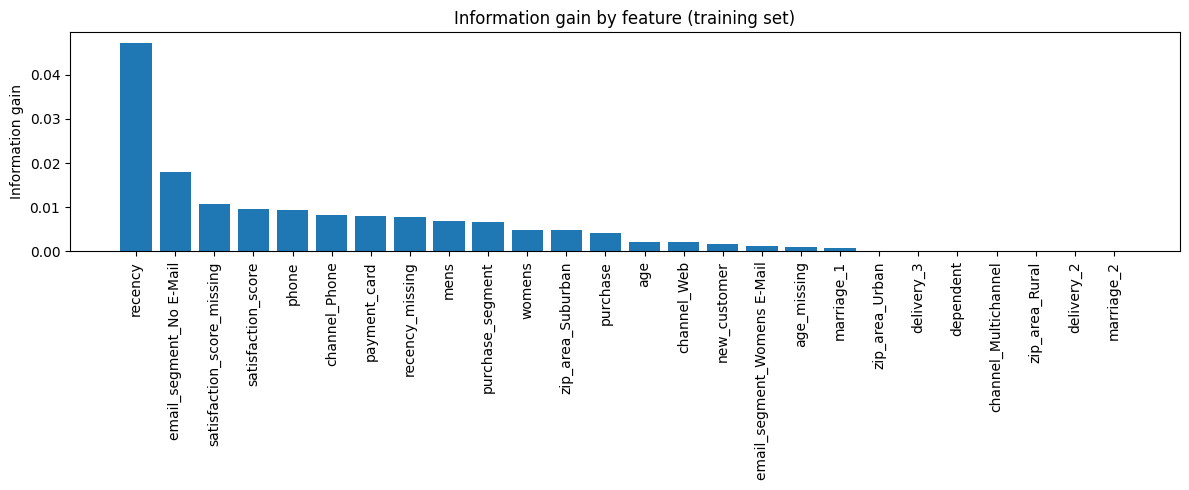

In [53]:
# Plot the information gain values in decreasing order
plt.figure(figsize=(12, 5))
plt.bar(weights.index, weights["attr_importance"])
plt.xticks(rotation=90)
plt.ylabel("Information gain")
plt.title("Information gain by feature (training set)")
plt.tight_layout()
plt.show()

**Findings:**
- `recency` (months since last purchase) is the most informative feature (0.042), followed by whether the customer got **no e-mail** (0.015) and `satisfaction_score` (0.012).
- Many features carry very little information on their own. Only 5 are above an illustrative threshold of 0.005.
- `email_segment_Womens E-Mail` scores almost zero (0.0002).

**Justification: we keep all features.**
- some features might be more useful when put in combination with another feature.
- since there's only 26 features for 36,400 customers, all of them are critical for the modelling process.